# Apex3D · 01 · Stanford Cars classifier training

**Owner:** Person A · **Problem:** P5 fine-grained vehicle recognition · **Output:** the checkpoint the app loads.

This notebook runs top to bottom and its saved outputs are the evidence for every classifier number we report.
Nothing here is hardcoded: metrics are computed below and written to `results/classifier_metrics.json`, which the app reads.

| # | Section | # | Section |
|---|---|---|---|
| 1 | Setup, reproducibility, hardware | 11 | Model choice and transfer learning |
| 2 | Dataset acquisition and file check | 12 | Stage 1: train the head |
| 3 | Annotation parsing | 13 | Stage 2: full fine-tuning |
| 4 | Test-label sanity check | 14 | Training curves |
| 5 | Exploratory data analysis | 15 | Validation results |
| 6 | Label structure: make, model, year | 16 | Calibration and confidence thresholds |
| 7 | Stratified train/validation split | 17 | Test evaluation (unseen data) |
| 8 | Preprocessing: box crops | 18 | Model size and inference time |
| 9 | Augmentation | 19 | Export for the app and the team |
| 10 | Data loaders | | |


## 1. Setup, reproducibility, hardware

In [1]:
import os, sys, json, time, math, random, platform
from pathlib import Path

REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "notebooks" / "cls_lib.py").exists())
sys.path.insert(0, str(REPO / "notebooks"))

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import torch, torchvision, timm, sklearn
from PIL import Image

import cls_lib as L

# ---- configuration (every tunable value lives here) ----
DATA_DIR   = Path(os.environ.get("APEX3D_DATA", REPO / "data" / "raw"))
CACHE_DIR  = REPO / "data" / "crops"
CKPT_DIR   = REPO / "checkpoints"
ART_DIR    = REPO / "artifacts"          # large outputs, shared via team drive (gitignored)
RESULTS    = REPO / "results"            # small JSON + plots, committed
PLOTS      = RESULTS / "plots"
for d in (CACHE_DIR, CKPT_DIR, ART_DIR, PLOTS):
    d.mkdir(parents=True, exist_ok=True)

ARCH            = "convnext_tiny.fb_in22k_ft_in1k"
IMG_SIZE        = 224
CACHE_MAX_SIDE  = 448      # cached crops are >= 2x the training size
BATCH           = 32
EFFECTIVE_BATCH = 64       # gradient accumulation if BATCH is smaller
NUM_WORKERS     = 2        # Windows workers each reserve ~1 GB of commit memory
HEAD_EPOCHS     = 2
FT_EPOCHS       = 30
PATIENCE        = 5        # early stopping on validation Top-1
LR_HEAD         = 1e-3
LR_FT           = 3e-4     # peak LR for the head group; earlier layers get less (layer decay)
LAYER_DECAY     = 0.9
WEIGHT_DECAY    = 0.05
LABEL_SMOOTHING = 0.1
WARMUP_EPOCHS   = 1
VAL_FRACTION    = 0.15
SEED            = 42

def seed_everything(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
seed_everything(SEED)
torch.backends.cudnn.benchmark = True    # fixed input size: faster; tiny run-to-run nondeterminism

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
env = {
    "python": platform.python_version(), "torch": torch.__version__, "torchvision": torchvision.__version__,
    "timm": timm.__version__, "sklearn": sklearn.__version__, "device": DEVICE,
    "gpu": torch.cuda.get_device_name(0) if DEVICE == "cuda" else None,
    "gpu_vram_gib": round(torch.cuda.get_device_properties(0).total_memory / 2**30, 2) if DEVICE == "cuda" else None,
    "cpu": platform.processor(), "os": platform.platform(),
}
print(json.dumps(env, indent=2))
NOTEBOOK_START = time.time()

{
  "python": "3.12.4",
  "torch": "2.11.0+cu128",
  "torchvision": "0.26.0+cu128",
  "timm": "1.0.31",
  "sklearn": "1.9.1",
  "device": "cuda",
  "gpu": "NVIDIA GeForce RTX 3050 Laptop GPU",
  "gpu_vram_gib": 4.0,
  "cpu": "Intel64 Family 6 Model 154 Stepping 3, GenuineIntel",
  "os": "Windows-11-10.0.26300-SP0"
}


## 2. Dataset acquisition and file check

Stanford Cars (Krause et al., 2013): 16,185 images, 196 classes, 8,144 train / 8,041 test.
The original Stanford URL and torchvision's downloader are broken, and the Kaggle mirror named in the proposal (`jessicali9530/stanford-cars-dataset`) returned *403 Forbidden* on 2026-11-06.
We use the Kaggle mirror **`rickyyyyyyy/torchvision-stanford-cars`**, which packages the same images in torchvision's layout, including `cars_test_annos_withlabels.mat`.

```
kaggle datasets download rickyyyyyyy/torchvision-stanford-cars -p data/raw --unzip
```
The cell below checks the counts we expect rather than trusting the mirror.

In [2]:
ROOT = L.find_stanford_root(DATA_DIR)
print("dataset root:", ROOT)
for p in sorted(ROOT.rglob("*")):
    if p.is_file() and p.suffix != ".jpg":
        print(f"  {p.relative_to(ROOT)}  ({p.stat().st_size/1e6:.2f} MB)")
n_train_jpg = len(list(L._image_dir(ROOT, "train").glob("*.jpg")))
n_test_jpg  = len(list(L._image_dir(ROOT, "test").glob("*.jpg")))
print("train jpgs:", n_train_jpg, " test jpgs:", n_test_jpg)
assert n_train_jpg == 8144 and n_test_jpg == 8041, "unexpected image counts"

dataset root: C:\Users\Shreyaskm\Apex3D\data\raw\stanford_cars


  cars_test_annos_withlabels.mat  (0.19 MB)


  devkit\cars_meta.mat  (0.00 MB)
  devkit\cars_test_annos.mat  (0.16 MB)
  devkit\cars_train_annos.mat  (0.19 MB)
  devkit\eval_train.m  (0.00 MB)
  devkit\README.txt  (0.00 MB)
  devkit\train_perfect_preds.txt  (0.03 MB)
train jpgs: 8144  test jpgs: 8041


## 3. Annotation parsing

Labels come from the devkit `.mat` files. Each record keeps its bounding box, because we train on the annotated vehicle region (the app classifies the detector's crop).

In [3]:
class_names = L.load_class_names(ROOT)
train_all = L.load_split(ROOT, "train")
test_recs = L.load_split(ROOT, "test")
print(len(class_names), "classes;", len(train_all), "train records;", len(test_recs), "test records")
missing = [r.path for r in train_all + test_recs if not Path(r.path).exists()]
print("missing files:", len(missing))
assert len(class_names) == 196 and not missing
print("examples:", class_names[:3], "...", class_names[-2:])

196 classes; 8144 train records; 8041 test records


missing files: 0
examples: ['AM General Hummer SUV 2000', 'Acura RL Sedan 2012', 'Acura TL Sedan 2012'] ... ['Volvo XC90 SUV 2007', 'smart fortwo Convertible 2012']


## 4. Test-label sanity check

The official devkit ships test annotations **without** labels; `cars_test_annos_withlabels.mat` comes from a third party.
Before trusting it we check: every class is present, labels are in range, and the per-class test counts track the per-class train counts (Stanford split each class roughly 50/50).
A final check comes in section 17: if test accuracy were far below validation accuracy, the labels would be suspect.

In [4]:
tr_counts = np.bincount([r.label for r in train_all], minlength=196)
te_counts = np.bincount([r.label for r in test_recs], minlength=196)
labels_in_range = all(0 <= r.label < 196 for r in train_all + test_recs)
corr = float(np.corrcoef(tr_counts, te_counts)[0, 1])
ratio = te_counts / tr_counts
bad_box = sum(1 for r in train_all + test_recs if r.bbox[2] <= r.bbox[0] or r.bbox[3] <= r.bbox[1])
print(f"labels in range: {labels_in_range}; classes in test: {(te_counts>0).sum()}/196")
print(f"per-class train/test count correlation: {corr:.3f}; test/train ratio min {ratio.min():.2f} max {ratio.max():.2f}")
print("degenerate boxes:", bad_box)
assert labels_in_range and (te_counts > 0).all() and corr > 0.9 and bad_box == 0
TEST_LABEL_CHECK = {"labels_in_range": labels_in_range, "classes_present": int((te_counts>0).sum()),
                    "train_test_count_corr": round(corr, 4), "degenerate_boxes": bad_box}

labels in range: True; classes in test: 196/196
per-class train/test count correlation: 0.993; test/train ratio min 0.96 max 1.00
degenerate boxes: 0


## 5. Exploratory data analysis

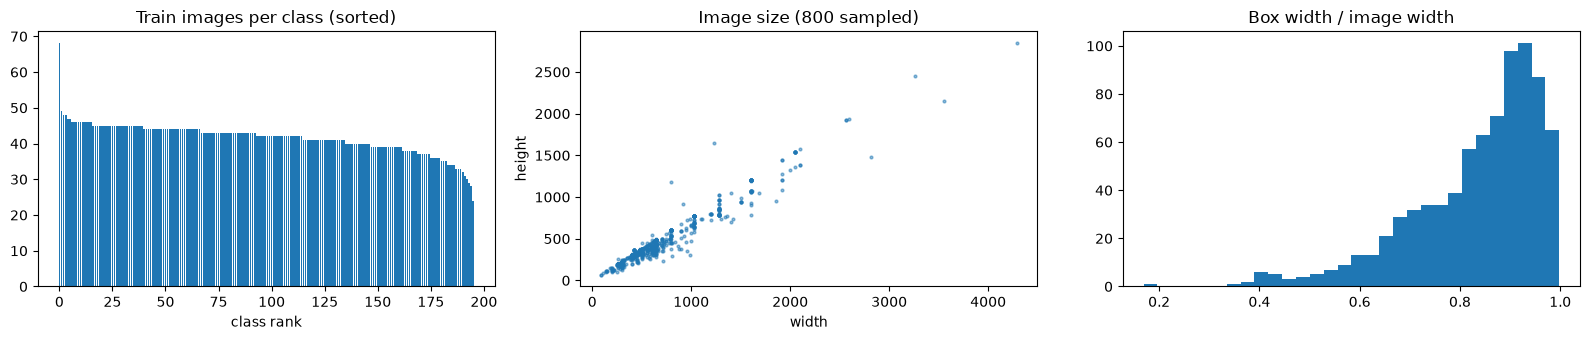

train images per class: min 24, median 42, max 68
median image size: 626 x 400


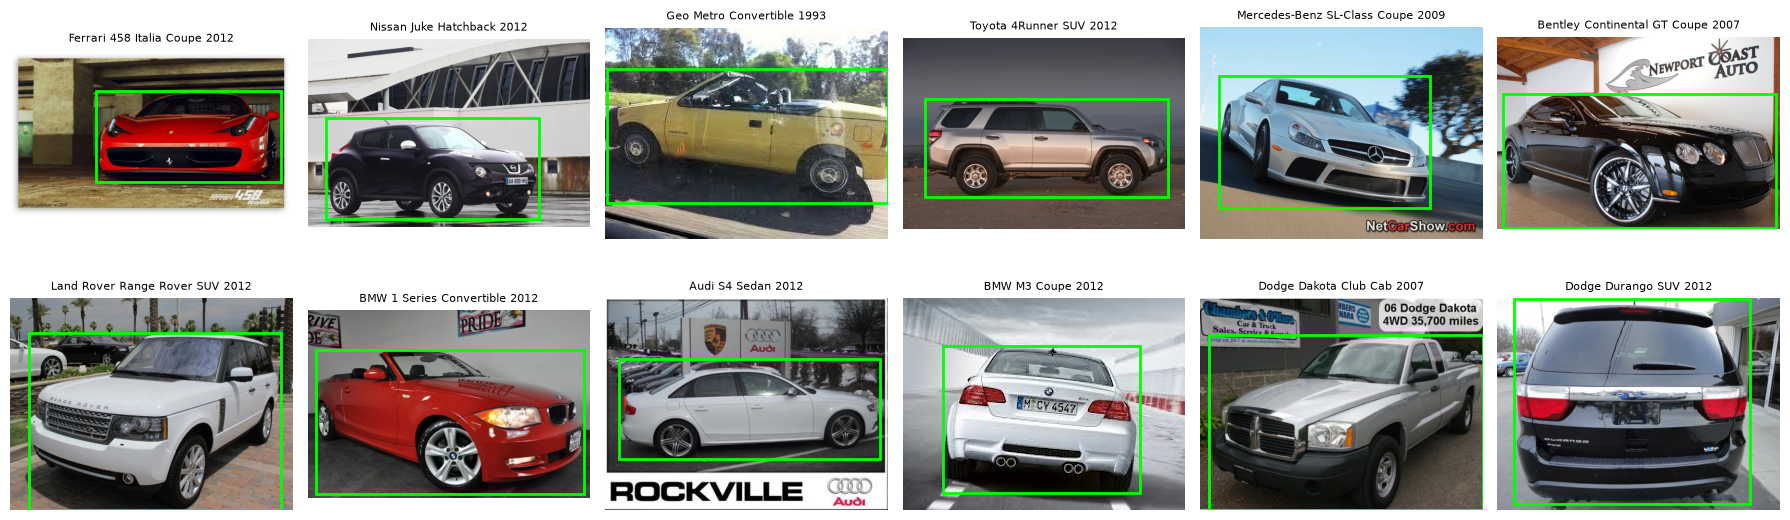

In [5]:
sizes = []
for r in random.Random(SEED).sample(train_all, 800):
    with Image.open(r.path) as im:
        sizes.append((im.width, im.height, (r.bbox[2]-r.bbox[0]) / im.width))
sizes = np.array(sizes)
fig, ax = plt.subplots(1, 3, figsize=(16, 3.5))
ax[0].bar(range(196), np.sort(tr_counts)[::-1]); ax[0].set_title("Train images per class (sorted)"); ax[0].set_xlabel("class rank")
ax[1].scatter(sizes[:, 0], sizes[:, 1], s=4, alpha=.5); ax[1].set_title("Image size (800 sampled)"); ax[1].set_xlabel("width"); ax[1].set_ylabel("height")
ax[2].hist(sizes[:, 2], bins=30); ax[2].set_title("Box width / image width")
plt.tight_layout(); plt.savefig(PLOTS / "eda_overview.png", dpi=110); plt.show()
print(f"train images per class: min {tr_counts.min()}, median {int(np.median(tr_counts))}, max {tr_counts.max()}")
print(f"median image size: {np.median(sizes[:,0]):.0f} x {np.median(sizes[:,1]):.0f}")

fig, axes = plt.subplots(2, 6, figsize=(18, 6))
for ax, r in zip(axes.flat, random.Random(1).sample(train_all, 12)):
    im = Image.open(r.path).convert("RGB"); ax.imshow(im)
    x1, y1, x2, y2 = r.bbox
    ax.add_patch(plt.Rectangle((x1, y1), x2-x1, y2-y1, fill=False, color="lime", lw=2))
    ax.set_title(class_names[r.label], fontsize=8); ax.axis("off")
plt.tight_layout(); plt.savefig(PLOTS / "eda_samples.png", dpi=90); plt.show()

## 6. Label structure: make, model, year

Each class name is *Make Model Type Year*. The year is a label attribute (the model year as labelled), not a learned generation estimate.
We report make-level accuracy and how many errors are year-only confusions.

In [6]:
meta = pd.DataFrame([L.parse_class_name(n) for n in class_names])
meta["class_id"] = range(196)
print("makes:", meta.make.nunique(), "| years:", int(meta.year.min()), "-", int(meta.year.max()))
same_model_diff_year = meta.groupby(["make", "model"]).year.nunique()
print("make+model groups with >1 year:", int((same_model_diff_year > 1).sum()))
display(meta.make.value_counts().head(10).to_frame("classes"))
display(meta.head(8))

makes: 49 | years: 1991 - 2012
make+model groups with >1 year: 7


,classes
make,
Chevrolet,22
Dodge,15
Audi,14
BMW,13
Ford,12
Hyundai,11
Acura,6
Bentley,6
Chrysler,6


,name,make,model,year,class_id
0,AM General Hummer SUV 2000,AM General,Hummer SUV,2000,0
1,Acura RL Sedan 2012,Acura,RL Sedan,2012,1
2,Acura TL Sedan 2012,Acura,TL Sedan,2012,2
3,Acura TL Type-S 2008,Acura,TL Type-S,2008,3
4,Acura TSX Sedan 2012,Acura,TSX Sedan,2012,4
5,Acura Integra Type R 2001,Acura,Integra Type R,2001,5
6,Acura ZDX Hatchback 2012,Acura,ZDX Hatchback,2012,6
7,Aston Martin V8 Vantage Convertible 2012,Aston Martin,V8 Vantage Convertible,2012,7


## 7. Stratified train/validation split

85/15 stratified split of the 8,144 training images. **All tuning uses validation; the test set is used only once, in section 17.**
The split is saved to `results/split.json` so Person B's classical and hybrid models use exactly the same images.

In [7]:
from sklearn.model_selection import train_test_split
idx = np.arange(len(train_all))
tr_idx, va_idx = train_test_split(idx, test_size=VAL_FRACTION, stratify=[r.label for r in train_all], random_state=SEED)
train_recs = [train_all[i] for i in tr_idx]; val_recs = [train_all[i] for i in va_idx]
print(len(train_recs), "train /", len(val_recs), "val /", len(test_recs), "test")
split = {"seed": SEED, "val_fraction": VAL_FRACTION,
         "train": sorted(Path(train_all[i].path).name for i in tr_idx),
         "val":   sorted(Path(train_all[i].path).name for i in va_idx)}
(RESULTS / "split.json").write_text(json.dumps(split))
assert not set(split["train"]) & set(split["val"])

6922 train / 1222 val / 8041 test


## 8. Preprocessing: box crops

Each image is cropped to its annotated box plus an 8% margin, then downscaled so the longer side is at most 448 px and cached as JPEG.
This mirrors inference (detector crop → classifier) and keeps the slow decode of large originals out of the training loop.

cached 16185 crops in 26s


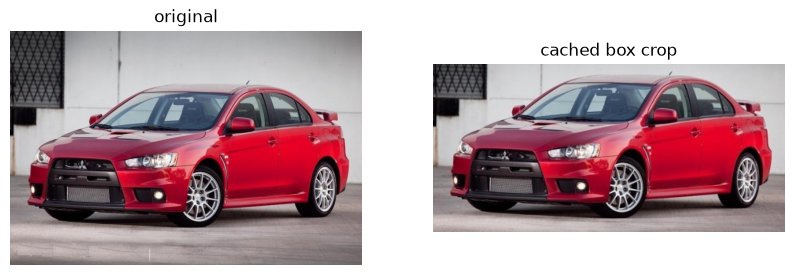

In [8]:
from concurrent.futures import ThreadPoolExecutor
t0 = time.time()
with ThreadPoolExecutor(8) as ex:
    def cache_all(recs):
        return list(ex.map(lambda r: L.cache_crop(r, CACHE_DIR, CACHE_MAX_SIDE), recs))
    tr_paths, va_paths, te_paths = cache_all(train_recs), cache_all(val_recs), cache_all(test_recs)
tr_y = [r.label for r in train_recs]; va_y = [r.label for r in val_recs]; te_y = [r.label for r in test_recs]
print(f"cached {len(tr_paths)+len(va_paths)+len(te_paths)} crops in {time.time()-t0:.0f}s")
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].imshow(Image.open(train_recs[0].path)); ax[0].set_title("original"); ax[0].axis("off")
ax[1].imshow(Image.open(tr_paths[0])); ax[1].set_title("cached box crop"); ax[1].axis("off")
plt.show()

## 9. Augmentation

RandomResizedCrop (scale 0.6–1), horizontal flip, RandAugment (2 ops, magnitude 9), and random erasing (also a cheap stand-in for occlusion).
Evaluation resizes the whole crop to a square; a centre crop would cut off the ends of wide car images.

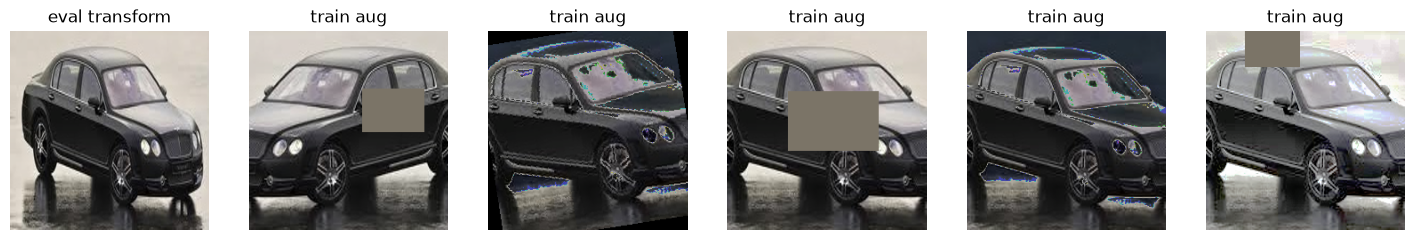

In [9]:
tf_train, tf_eval = L.train_transform(IMG_SIZE), L.eval_transform(IMG_SIZE)
def denorm(t): return (t.permute(1, 2, 0).numpy() * L.IMAGENET_STD + L.IMAGENET_MEAN).clip(0, 1)
src = Image.open(tr_paths[5]).convert("RGB")
fig, axes = plt.subplots(1, 6, figsize=(18, 3))
axes[0].imshow(denorm(tf_eval(src))); axes[0].set_title("eval transform")
for a in axes[1:]: a.imshow(denorm(tf_train(src))); a.set_title("train aug")
for a in axes: a.axis("off")
plt.savefig(PLOTS / "augmentations.png", dpi=90); plt.show()

## 10. Data loaders

In [10]:
from torch.utils.data import DataLoader
def loader(paths, ys, tf, shuffle, bs=BATCH, persistent=False):
    # persistent workers only for loaders reused every epoch (Windows workers are memory-heavy)
    return DataLoader(L.CropDataset(paths, ys, tf), batch_size=bs, shuffle=shuffle, num_workers=NUM_WORKERS,
                      pin_memory=True, persistent_workers=persistent, drop_last=shuffle)
dl_train = loader(tr_paths, tr_y, tf_train, True, persistent=True)
dl_val   = loader(va_paths, va_y, tf_eval, False, bs=64, persistent=True)
xb, yb = next(iter(dl_train)); print("batch:", tuple(xb.shape), xb.dtype, "labels:", yb[:8].tolist())

batch: (32, 3, 224, 224) torch.float32 labels: [186, 41, 187, 86, 187, 1, 154, 113]


## 11. Model choice and transfer learning

**ConvNeXt-Tiny** (`timm` `convnext_tiny.fb_in22k_ft_in1k`; Facebook ConvNeXt weights, MIT licence; 28M parameters), pretrained on ImageNet-22k and fine-tuned on ImageNet-1k.
It is accurate for its size and fits the team laptop's 4 GB GPU at 224 px.
The ImageNet classifier is replaced by a new 196-way head.

The laptop GPU has 4 GB of VRAM, so we probe the batch size first and enable gradient checkpointing only if a 32-image batch does not fit.

In [11]:
model = L.build_model(ARCH, 196, pretrained=True).to(DEVICE).to(memory_format=torch.channels_last)
n_params = sum(p.numel() for p in model.parameters())
print(f"{ARCH}: {n_params/1e6:.1f}M parameters; head: {model.get_classifier()}")

def probe(bs):
    torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()
    x = torch.randn(bs, 3, IMG_SIZE, IMG_SIZE, device=DEVICE).to(memory_format=torch.channels_last)
    with torch.autocast("cuda", dtype=torch.float16):
        model(x).float().mean().backward()
    model.zero_grad(set_to_none=True)
    return torch.cuda.max_memory_allocated() / 2**30

GRAD_CKPT = False
if DEVICE == "cuda":
    model.train()
    try:
        print(f"peak VRAM at batch {BATCH}: {probe(BATCH):.2f} GiB")
    except torch.cuda.OutOfMemoryError:
        GRAD_CKPT = True; model.set_grad_checkpointing(True); torch.cuda.empty_cache()
        print(f"batch {BATCH} did not fit; gradient checkpointing on -> peak {probe(BATCH):.2f} GiB")
ACCUM = max(1, EFFECTIVE_BATCH // BATCH)
print("grad checkpointing:", GRAD_CKPT, "| accumulation steps:", ACCUM)

convnext_tiny.fb_in22k_ft_in1k: 28.0M parameters; head: Linear(in_features=768, out_features=196, bias=True)


peak VRAM at batch 32: 2.06 GiB
grad checkpointing: False | accumulation steps: 2


Shared training and evaluation loops (mixed precision, label smoothing, gradient accumulation).

In [12]:
import torch.nn as nn, torch.nn.functional as F
criterion = nn.CrossEntropyLoss(label_smoothing=LABEL_SMOOTHING)
scaler = torch.amp.GradScaler("cuda", enabled=DEVICE == "cuda")

def train_one_epoch(model, dl, opt, sched=None, epoch=0):
    model.train(); tot, correct, loss_sum = 0, 0, 0.0
    steps_per_epoch = len(dl) // ACCUM
    opt.zero_grad(set_to_none=True)
    for i, (x, y) in enumerate(dl):
        x = x.to(DEVICE, non_blocking=True).to(memory_format=torch.channels_last); y = y.to(DEVICE, non_blocking=True)
        with torch.autocast("cuda", dtype=torch.float16, enabled=DEVICE == "cuda"):
            out = model(x); loss = criterion(out, y) / ACCUM
        scaler.scale(loss).backward()
        if (i + 1) % ACCUM == 0:
            scaler.unscale_(opt); nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update(); opt.zero_grad(set_to_none=True)
            if sched is not None: sched.step_update(epoch * steps_per_epoch + (i + 1) // ACCUM)
        loss_sum += loss.item() * ACCUM * len(y); tot += len(y); correct += (out.argmax(1) == y).sum().item()
    return loss_sum / tot, correct / tot

@torch.no_grad()
def predict(model, dl, with_features=False):
    model.eval(); logits, feats, ys = [], [], []
    for x, y in dl:
        x = x.to(DEVICE, non_blocking=True).to(memory_format=torch.channels_last)
        with torch.autocast("cuda", dtype=torch.float16, enabled=DEVICE == "cuda"):
            f = model.forward_head(model.forward_features(x), pre_logits=True)
            out = model.get_classifier()(f)
        logits.append(out.float().cpu()); ys.append(y)
        if with_features: feats.append(f.float().cpu())
    res = (torch.cat(logits), torch.cat(ys))
    return res + (torch.cat(feats),) if with_features else res

def topk_acc(logits, y, k): return (logits.topk(k, 1).indices == y[:, None]).any(1).float().mean().item()
history = []

## 12. Stage 1: train the head

The backbone is frozen and only the new classifier learns, so the random head does not send large gradients into the pretrained features.

In [13]:
for p in model.parameters(): p.requires_grad = False
for p in model.get_classifier().parameters(): p.requires_grad = True
opt = torch.optim.AdamW(model.get_classifier().parameters(), lr=LR_HEAD, weight_decay=WEIGHT_DECAY)
t_stage1 = time.time()
for ep in range(HEAD_EPOCHS):
    t0 = time.time(); tl, ta = train_one_epoch(model, dl_train, opt)
    vlog, vy = predict(model, dl_val); vl = F.cross_entropy(vlog, vy).item()
    history.append({"stage": 1, "epoch": len(history) + 1, "train_loss": tl, "train_acc": ta, "val_loss": vl,
                    "val_top1": topk_acc(vlog, vy, 1), "val_top5": topk_acc(vlog, vy, 5), "lr": LR_HEAD, "sec": time.time() - t0})
    print({k: round(v, 4) if isinstance(v, float) else v for k, v in history[-1].items()})
STAGE1_MIN = (time.time() - t_stage1) / 60

{'stage': 1, 'epoch': 1, 'train_loss': 4.6561, 'train_acc': 0.0859, 'val_loss': 3.0508, 'val_top1': 0.2594, 'val_top5': 0.5974, 'lr': 0.001, 'sec': 54.2805}


{'stage': 1, 'epoch': 2, 'train_loss': 3.9185, 'train_acc': 0.2251, 'val_loss': 2.5035, 'val_top1': 0.3961, 'val_top5': 0.7087, 'lr': 0.001, 'sec': 19.4946}


## 13. Stage 2: full fine-tuning

All layers are unfrozen. AdamW with **layer-wise learning-rate decay** (deeper, more generic layers learn more slowly), a cosine schedule with one warm-up epoch, label smoothing 0.1 and mixed precision.
**Early stopping** keeps the epoch with the best validation Top-1 and stops after 5 epochs without improvement.

In [14]:
from timm.optim import create_optimizer_v2
from timm.scheduler import CosineLRScheduler
for p in model.parameters(): p.requires_grad = True
opt = create_optimizer_v2(model, opt="adamw", lr=LR_FT, weight_decay=WEIGHT_DECAY, layer_decay=LAYER_DECAY)
steps_per_epoch = len(dl_train) // ACCUM
sched = CosineLRScheduler(opt, t_initial=FT_EPOCHS * steps_per_epoch, lr_min=1e-6,
                          warmup_t=WARMUP_EPOCHS * steps_per_epoch, warmup_lr_init=1e-6, t_in_epochs=False)
BEST_PATH = CKPT_DIR / "best_stage2_state.pt"
best_top1, best_epoch, bad = -1.0, None, 0
t_stage2 = time.time()
for ep in range(FT_EPOCHS):
    t0 = time.time(); tl, ta = train_one_epoch(model, dl_train, opt, sched, ep)
    vlog, vy = predict(model, dl_val); vl = F.cross_entropy(vlog, vy).item(); v1 = topk_acc(vlog, vy, 1)
    history.append({"stage": 2, "epoch": len(history) + 1, "train_loss": tl, "train_acc": ta, "val_loss": vl,
                    "val_top1": v1, "val_top5": topk_acc(vlog, vy, 5), "lr": max(g["lr"] for g in opt.param_groups), "sec": time.time() - t0})
    print({k: round(v, 4) if isinstance(v, float) else v for k, v in history[-1].items()}, flush=True)
    if v1 > best_top1:
        best_top1, best_epoch, bad = v1, history[-1]["epoch"], 0
        torch.save(model.state_dict(), BEST_PATH)
    else:
        bad += 1
        if bad >= PATIENCE:
            print(f"early stop: no val improvement for {PATIENCE} epochs"); break
STAGE2_MIN = (time.time() - t_stage2) / 60
model.load_state_dict(torch.load(BEST_PATH, map_location=DEVICE))
print(f"best val Top-1 {best_top1:.4f} at epoch {best_epoch}; stage 2 took {STAGE2_MIN:.1f} min")

{'stage': 2, 'epoch': 3, 'train_loss': 3.1527, 'train_acc': 0.4384, 'val_loss': 1.6396, 'val_top1': 0.6121, 'val_top5': 0.8944, 'lr': 0.0003, 'sec': 50.3473}


{'stage': 2, 'epoch': 4, 'train_loss': 2.3329, 'train_acc': 0.661, 'val_loss': 1.0822, 'val_top1': 0.7414, 'val_top5': 0.9394, 'lr': 0.0003, 'sec': 51.3693}


{'stage': 2, 'epoch': 5, 'train_loss': 1.8126, 'train_acc': 0.8027, 'val_loss': 0.8877, 'val_top1': 0.7856, 'val_top5': 0.9566, 'lr': 0.0003, 'sec': 52.1104}


{'stage': 2, 'epoch': 6, 'train_loss': 1.4949, 'train_acc': 0.885, 'val_loss': 0.7847, 'val_top1': 0.8486, 'val_top5': 0.9681, 'lr': 0.0003, 'sec': 56.6254}


{'stage': 2, 'epoch': 7, 'train_loss': 1.3361, 'train_acc': 0.9235, 'val_loss': 0.6282, 'val_top1': 0.8699, 'val_top5': 0.9787, 'lr': 0.0003, 'sec': 64.4676}


{'stage': 2, 'epoch': 8, 'train_loss': 1.2269, 'train_acc': 0.9492, 'val_loss': 0.6519, 'val_top1': 0.8666, 'val_top5': 0.9795, 'lr': 0.0003, 'sec': 64.7773}


... (21 outputs left out)

{'stage': 2, 'epoch': 30, 'train_loss': 0.9233, 'train_acc': 0.9974, 'val_loss': 0.5934, 'val_top1': 0.9198, 'val_top5': 0.9885, 'lr': 0.0, 'sec': 64.0416}


{'stage': 2, 'epoch': 31, 'train_loss': 0.9226, 'train_acc': 0.9965, 'val_loss': 0.5922, 'val_top1': 0.9223, 'val_top5': 0.9885, 'lr': 0.0, 'sec': 63.6606}


{'stage': 2, 'epoch': 32, 'train_loss': 0.9205, 'train_acc': 0.9965, 'val_loss': 0.5948, 'val_top1': 0.9223, 'val_top5': 0.9885, 'lr': 0.0, 'sec': 52.4242}


best val Top-1 0.9223 at epoch 28; stage 2 took 183.3 min


## 14. Training curves

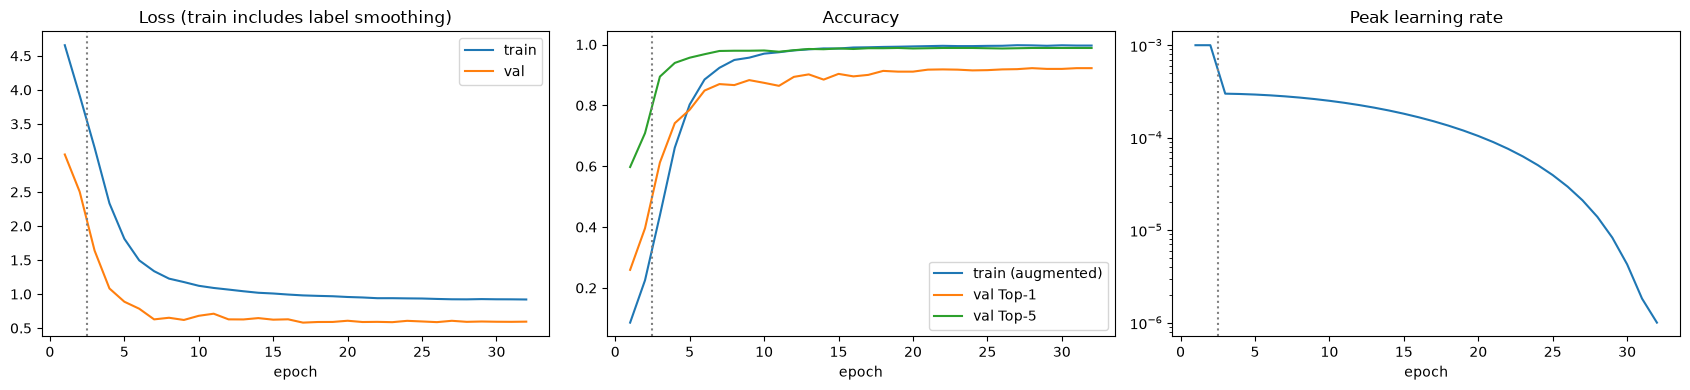

In [15]:
h = pd.DataFrame(history); h.to_csv(RESULTS / "classifier_history.csv", index=False)
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
ax[0].plot(h.epoch, h.train_loss, label="train"); ax[0].plot(h.epoch, h.val_loss, label="val"); ax[0].set_title("Loss (train includes label smoothing)")
ax[1].plot(h.epoch, h.train_acc, label="train (augmented)"); ax[1].plot(h.epoch, h.val_top1, label="val Top-1"); ax[1].plot(h.epoch, h.val_top5, label="val Top-5"); ax[1].set_title("Accuracy")
ax[2].plot(h.epoch, h.lr); ax[2].set_title("Peak learning rate"); ax[2].set_yscale("log")
for a in ax: a.set_xlabel("epoch"); a.axvline(HEAD_EPOCHS + .5, color="grey", ls=":")
ax[0].legend(); ax[1].legend(); plt.tight_layout(); plt.savefig(PLOTS / "training_curves.png", dpi=110); plt.show()

## 15. Validation results

In [16]:
val_logits, val_y = predict(model, dl_val)
VAL = {"top1": topk_acc(val_logits, val_y, 1), "top5": topk_acc(val_logits, val_y, 5), "n": len(val_y)}
print(VAL)

{'top1': 0.9222586154937744, 'top5': 0.9885433912277222, 'n': 1222}


## 16. Calibration and confidence thresholds

Softmax confidence from fine-tuned networks is often over- or under-confident. **Temperature scaling** (Guo et al., 2017) fits one scalar *T* on validation logits so that the probabilities become better calibrated; it does not change the predicted class.

The app then sorts each prediction into one of three states using the calibrated Top-1 probability *p1* and the margin *p1 − p2*, with thresholds chosen on validation:
- **confident:** the (p1, margin) pair with the highest coverage among those whose accepted predictions are at least 95% accurate on validation;
- **rejected:** p1 below the largest threshold under which validation predictions are wrong at least half the time (needs ≥ 20 samples);
- **ambiguous:** everything in between; the app shows the Top-5 and asks the user to confirm.

Validation contains only in-taxonomy cars, so these thresholds do **not** prove that out-of-taxonomy vehicles are rejected. That has to be checked separately on non-Stanford images.

{'temperature': 0.6166, 'val_nll_before': 0.5921, 'val_nll_after': 0.3651, 'val_ece_before': 0.2075, 'val_ece_after': 0.034}
confident   93.4% of val, accuracy 0.950
ambiguous    1.0% of val, accuracy 0.833
rejected     5.6% of val, accuracy 0.478
{'confident_p1': 0.52, 'confident_margin': 0.34, 'reject_below_p1': 0.52, 'val_confident_coverage': 0.9337152209492635, 'val_confident_accuracy': 0.9500438212094654, 'reject_rule_note': 'chosen on validation'}


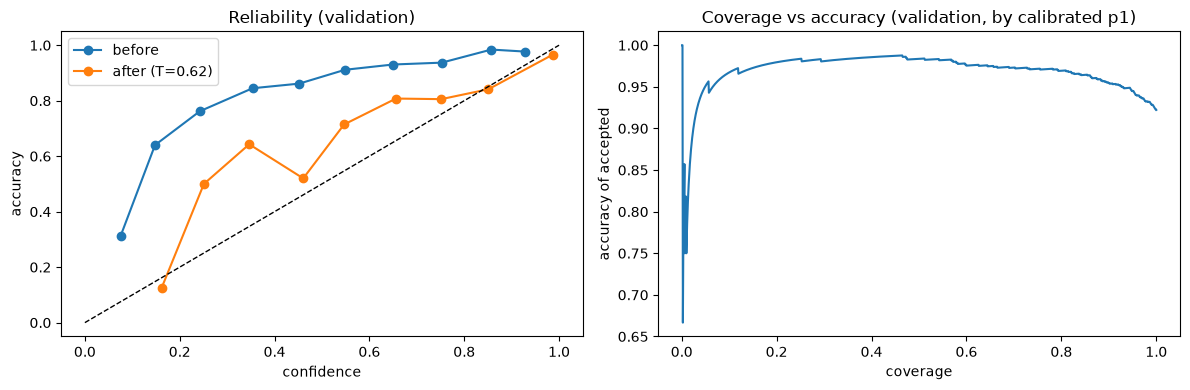

In [17]:
def nll(logits, y, T): return F.cross_entropy(logits / T, y).item()
def ece(probs, y, bins=15):
    conf, pred = probs.max(1); acc = (pred == y).float(); e = 0.0
    edges = torch.linspace(0, 1, bins + 1)
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any(): e += m.float().mean().item() * abs(acc[m].mean().item() - conf[m].mean().item())
    return e

logT = torch.zeros(1, requires_grad=True)
opt_t = torch.optim.LBFGS([logT], lr=0.1, max_iter=200)
def closure():
    opt_t.zero_grad(); loss = F.cross_entropy(val_logits / logT.exp(), val_y); loss.backward(); return loss
opt_t.step(closure)
TEMP = logT.detach().exp().item()
CAL = {"temperature": TEMP, "val_nll_before": nll(val_logits, val_y, 1.0), "val_nll_after": nll(val_logits, val_y, TEMP),
       "val_ece_before": ece(val_logits.softmax(1), val_y), "val_ece_after": ece((val_logits / TEMP).softmax(1), val_y)}
print({k: round(v, 4) for k, v in CAL.items()})

vp = (val_logits / TEMP).softmax(1); top2 = vp.topk(2, 1)
p1, margin, correct = top2.values[:, 0].numpy(), (top2.values[:, 0] - top2.values[:, 1]).numpy(), (top2.indices[:, 0] == val_y).numpy()
grid = np.round(np.arange(0.05, 1.0, 0.01), 2)
best = None
for t in grid:
    for m in np.round(np.arange(0.0, 0.9, 0.02), 2):
        acc_mask = (p1 >= t) & (margin >= m)
        if acc_mask.sum() < 30: continue
        a, cov = correct[acc_mask].mean(), acc_mask.mean()
        if a >= 0.95 and (best is None or cov > best[2]): best = (float(t), float(m), float(cov), float(a))
reject_t = float(grid[0]); reject_note = "no threshold met the rule; minimum grid value used"
for t in grid:
    below = p1 < t
    if below.sum() >= 20 and correct[below].mean() <= 0.5: reject_t, reject_note = float(t), "chosen on validation"
assert best is not None, "no confident threshold reaches 95% accuracy on validation"
THRESHOLDS = {"confident_p1": best[0], "confident_margin": best[1], "reject_below_p1": min(reject_t, best[0]),
              "val_confident_coverage": best[2], "val_confident_accuracy": best[3], "reject_rule_note": reject_note}
states = np.array([L.confidence_state(sorted(r, reverse=True)[:2], THRESHOLDS) for r in vp.numpy()])
for s in ("confident", "ambiguous", "rejected"):
    msk = states == s
    print(f"{s:10s} {msk.mean():6.1%} of val, accuracy {correct[msk].mean() if msk.any() else float('nan'):.3f}")
print(THRESHOLDS)

order = np.argsort(-p1); cum_acc = np.cumsum(correct[order]) / np.arange(1, len(order) + 1); coverage = np.arange(1, len(order) + 1) / len(order)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for lab, pr in (("before", val_logits.softmax(1)), (f"after (T={TEMP:.2f})", vp)):
    conf, pred = pr.max(1); bins = np.linspace(0, 1, 11); idxb = np.digitize(conf.numpy(), bins) - 1
    xs = [conf.numpy()[idxb == b].mean() for b in range(10) if (idxb == b).sum() > 0]
    ys_ = [(pred == val_y).numpy()[idxb == b].mean() for b in range(10) if (idxb == b).sum() > 0]
    ax[0].plot(xs, ys_, "o-", label=lab)
ax[0].plot([0, 1], [0, 1], "k--", lw=1); ax[0].set_title("Reliability (validation)"); ax[0].set_xlabel("confidence"); ax[0].set_ylabel("accuracy"); ax[0].legend()
ax[1].plot(coverage, cum_acc); ax[1].set_title("Coverage vs accuracy (validation, by calibrated p1)"); ax[1].set_xlabel("coverage"); ax[1].set_ylabel("accuracy of accepted")
plt.tight_layout(); plt.savefig(PLOTS / "calibration_coverage.png", dpi=110); plt.show()

## 17. Test evaluation (unseen data)

The held-out test set (8,041 images, never used for any decision above) is evaluated **once**, on ground-truth box crops.
Detector-crop accuracy is measured separately with the detector (Person B), using the logits exported in section 19.

In [18]:
dl_test = loader(te_paths, te_y, tf_eval, False, bs=64)
test_logits, test_y = predict(model, dl_test)
test_probs = (test_logits / TEMP).softmax(1); test_pred = test_probs.argmax(1).numpy(); yt = test_y.numpy()
TEST = {"top1": topk_acc(test_logits, test_y, 1), "top5": topk_acc(test_logits, test_y, 5), "n": len(yt),
        "nll_calibrated": nll(test_logits, test_y, TEMP), "ece_calibrated": ece(test_probs, test_y)}
make_of = meta.make.values; mm_of = (meta.make + " " + meta.model).values
TEST["make_top1"] = float((make_of[test_pred] == make_of[yt]).mean())
errs = test_pred != yt
TEST["errors_same_make_model_diff_year"] = float((mm_of[test_pred][errs] == mm_of[yt][errs]).mean())
TEST["errors_same_make"] = float((make_of[test_pred][errs] == make_of[yt][errs]).mean())
st = np.array([L.confidence_state(sorted(r, reverse=True)[:2], THRESHOLDS) for r in test_probs.numpy()])
TEST["states"] = {s: {"share": float((st == s).mean()), "accuracy": float((test_pred == yt)[st == s].mean()) if (st == s).any() else None}
                  for s in ("confident", "ambiguous", "rejected")}
print(json.dumps(TEST, indent=2))
gap = VAL["top1"] - TEST["top1"]
print(f"val-test Top-1 gap: {gap:+.3f}  (a large gap would cast doubt on the third-party test labels)")
TEST_LABEL_CHECK["val_minus_test_top1"] = round(gap, 4)

{
  "top1": 0.9220246076583862,
  "top5": 0.984205961227417,
  "n": 8041,
  "nll_calibrated": 0.36681392788887024,
  "ece_calibrated": 0.024038807013141684,
  "make_top1": 0.9715209551050864,
  "errors_same_make_model_diff_year": 0.06220095693779904,
  "errors_same_make": 0.6347687400318979,
  "states": {
    "confident": {
      "share": 0.9352070637980351,
      "accuracy": 0.9503989361702128
    },
    "ambiguous": {
      "share": 0.012684989429175475,
      "accuracy": 0.5980392156862745
    },
    "rejected": {
      "share": 0.05210794677278945,
      "accuracy": 0.4916467780429594
    }
  }
}
val-test Top-1 gap: +0.000  (a large gap would cast doubt on the third-party test labels)


macro P/R/F1: 0.9237 0.9213 0.9208

worst 10 classes by F1:


,name,precision,recall,f1,support
70,Chevrolet Express Van 2007,0.562500,0.514286,0.537313,35
63,Chevrolet Express Cargo Van 2007,0.586207,0.586207,0.586207,29
21,Audi S5 Coupe 2012,0.741935,0.547619,0.630137,42
16,Audi 100 Sedan 1994,0.576923,0.750000,0.652174,40
18,Audi TT Hatchback 2011,0.666667,0.650000,0.658228,40
13,Audi TTS Coupe 2012,0.722222,0.619048,0.666667,42
68,Chevrolet Silverado 2500HD Regular Cab 2012,0.607843,0.815789,0.696629,38
74,Chevrolet Silverado 1500 Regular Cab 2012,0.866667,0.590909,0.702703,44
17,Audi 100 Wagon 1994,0.923077,0.571429,0.705882,42
15,Audi V8 Sedan 1994,0.743590,0.674419,0.707317,43



most-confused pairs (test):


,class_a,class_b,a_as_b,b_as_a,total
0,Dodge Caliber Wagon 2012,Dodge Caliber Wagon 2007,9,11,20
1,Audi V8 Sedan 1994,Audi 100 Sedan 1994,12,8,20
2,Audi TTS Coupe 2012,Audi TT Hatchback 2011,11,7,18
3,Chevrolet Express Van 2007,GMC Savana Van 2012,9,8,17
4,Chevrolet Silverado 2500HD Regular Cab 2012,Chevrolet Silverado 1500 Regular Cab 2012,2,15,17
5,Audi A5 Coupe 2012,Audi S5 Coupe 2012,6,11,17
6,Chevrolet Express Cargo Van 2007,Chevrolet Express Van 2007,6,8,14
7,Bentley Continental GT Coupe 2012,Bentley Continental GT Coupe 2007,8,6,14
8,Dodge Sprinter Cargo Van 2009,Mercedes-Benz Sprinter Van 2012,8,5,13
9,Chevrolet Tahoe Hybrid SUV 2012,Chevrolet Avalanche Crew Cab 2012,9,4,13


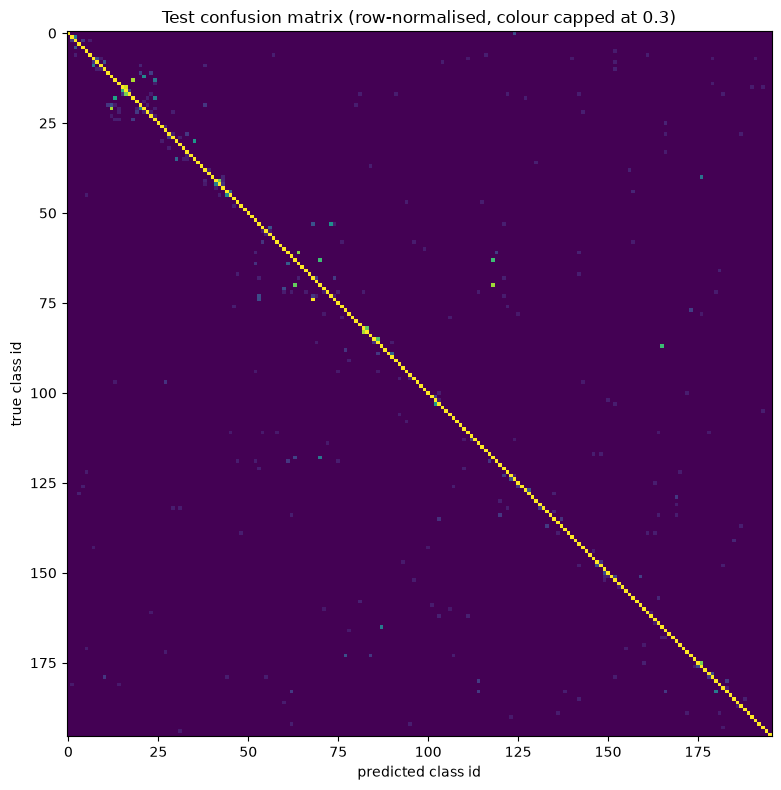

In [19]:
from sklearn.metrics import precision_recall_fscore_support, confusion_matrix
prec, rec, f1, sup = precision_recall_fscore_support(yt, test_pred, labels=range(196), zero_division=0)
per_class = pd.DataFrame({"class_id": range(196), "name": class_names, "precision": prec, "recall": rec, "f1": f1, "support": sup})
per_class.to_csv(RESULTS / "classifier_per_class.csv", index=False)
TEST["macro_precision"], TEST["macro_recall"], TEST["macro_f1"] = float(prec.mean()), float(rec.mean()), float(f1.mean())
print("macro P/R/F1:", round(prec.mean(), 4), round(rec.mean(), 4), round(f1.mean(), 4))
print("\nworst 10 classes by F1:"); display(per_class.sort_values("f1").head(10)[["name", "precision", "recall", "f1", "support"]])

cm = confusion_matrix(yt, test_pred, labels=range(196))
off = cm.copy(); np.fill_diagonal(off, 0)
pairs = sorted(((off[i, j] + off[j, i], i, j) for i in range(196) for j in range(i + 1, 196)), reverse=True)[:15]
confused = pd.DataFrame([{"class_a": class_names[i], "class_b": class_names[j], "a_as_b": int(off[i, j]), "b_as_a": int(off[j, i]), "total": int(n)} for n, i, j in pairs])
confused.to_csv(RESULTS / "classifier_confused_pairs.csv", index=False)
print("\nmost-confused pairs (test):"); display(confused)

fig, ax = plt.subplots(figsize=(9, 8))
cmn = cm / np.maximum(cm.sum(1, keepdims=True), 1)
ax.imshow(cmn, cmap="viridis", vmax=0.3); ax.set_title("Test confusion matrix (row-normalised, colour capped at 0.3)")
ax.set_xlabel("predicted class id"); ax.set_ylabel("true class id")
plt.tight_layout(); plt.savefig(PLOTS / "confusion_matrix.png", dpi=110); plt.show()

## 18. Model size and inference time

Single-image latency (batch 1, 224 px) after 10 warm-up runs, mean of 50. GPU: FP32 and FP16 autocast. CPU: FP32 with PyTorch's default thread count.
ONNX export and INT8 quantization are in `01b_export_quantize.ipynb`.

In [20]:
def bench(m, device, fp16=False, n=50):
    m = m.to(device).eval(); x = torch.randn(1, 3, IMG_SIZE, IMG_SIZE, device=device)
    with torch.no_grad(), torch.autocast("cuda", dtype=torch.float16, enabled=fp16):
        for _ in range(10): m(x)
        if device == "cuda": torch.cuda.synchronize()
        t0 = time.perf_counter()
        for _ in range(n): m(x)
        if device == "cuda": torch.cuda.synchronize()
    return (time.perf_counter() - t0) / n * 1000

if GRAD_CKPT: model.set_grad_checkpointing(False)
model = model.to(memory_format=torch.contiguous_format)
SPEED = {"cpu_threads": torch.get_num_threads()}
if DEVICE == "cuda":
    SPEED["gpu_fp32_ms"] = bench(model, "cuda"); SPEED["gpu_fp16_ms"] = bench(model, "cuda", fp16=True)
SPEED["cpu_fp32_ms"] = bench(model, "cpu", n=20)
model.to(DEVICE)
print({k: round(v, 2) for k, v in SPEED.items()})

{'cpu_threads': 12, 'gpu_fp32_ms': 5.24, 'gpu_fp16_ms': 5.94, 'cpu_fp32_ms': 56.29}


## 19. Export for the app and the team

| File | Goes to | In Git? |
|---|---|---|
| `checkpoints/apex3d_convnext_tiny.pt`: weights, architecture, input size, normalisation, class names, temperature, thresholds | App (Person C), via `cls_lib.load_classifier` | No (team drive) |
| `results/classifier_metrics.json`: every number above | App `/api/metrics`, eval file | Yes |
| `results/class_names.json`, `results/split.json`, CSVs, `results/plots/*.png` | Everyone | Yes |
| `artifacts/logits_*.npz`, `artifacts/embeddings_*.npz`: logits, 768-d pooled features, labels and file names for train/val/test | Person B (hybrid fusion, threshold analysis, ablation) | No (team drive) |

In [21]:
BUNDLE = CKPT_DIR / "apex3d_convnext_tiny.pt"
L.save_bundle(BUNDLE, model, arch=ARCH, img_size=IMG_SIZE, class_names=class_names, temperature=TEMP, thresholds=THRESHOLDS,
              extra={"best_epoch": best_epoch, "val_top1": VAL["top1"], "test_top1": TEST["top1"], "seed": SEED})
SIZE = {"params_m": n_params / 1e6, "checkpoint_mb": BUNDLE.stat().st_size / 1e6}
(RESULTS / "class_names.json").write_text(json.dumps([{"class_id": i, **L.parse_class_name(n)} for i, n in enumerate(class_names)], indent=1))

# embeddings + logits for Person B (train without augmentation)
dl_train_eval = loader(tr_paths, tr_y, tf_eval, False, bs=64)
for name, dl, paths in (("train", dl_train_eval, tr_paths), ("val", dl_val, va_paths), ("test", dl_test, te_paths)):
    lg, yy, ft = predict(model, dl, with_features=True)
    np.savez_compressed(ART_DIR / f"embeddings_{name}.npz", features=ft.half().numpy(), labels=yy.numpy(),
                        files=np.array([Path(p).name for p in paths]))
    np.savez_compressed(ART_DIR / f"logits_{name}.npz", logits=lg.numpy(), labels=yy.numpy(), files=np.array([Path(p).name for p in paths]))
    print(name, ft.shape)

# reload the bundle exactly as the app will and check it reproduces test predictions
clf = L.load_classifier(BUNDLE, DEVICE)
chk = [L.predict_crop(clf, Image.open(p))["topk"][0]["class_id"] for p in te_paths[:200]]
agree = float(np.mean(np.array(chk) == test_pred[:200]))
print(f"reloaded bundle agrees with notebook predictions on {agree:.1%} of 200 test crops")
# the app runs FP32 while the notebook evaluated with FP16 autocast, so a near-tie can flip
assert agree >= 0.97

METRICS = {
    "generated_by": "notebooks/01_classifier_training.ipynb",
    "generated_at": time.strftime("%Y-%m-%d %H:%M:%S"),
    "environment": env,
    "dataset": {"name": "Stanford Cars", "source": "kaggle:rickyyyyyyy/torchvision-stanford-cars", "classes": 196,
                "train": len(train_recs), "val": len(val_recs), "test": len(test_recs), "input": "ground-truth box crop + 8% margin",
                "test_label_check": TEST_LABEL_CHECK},
    "model": {"arch": ARCH, "img_size": IMG_SIZE, "pretrained": "ImageNet-22k -> ImageNet-1k (timm)", **SIZE},
    "training": {"head_epochs": HEAD_EPOCHS, "max_ft_epochs": FT_EPOCHS, "epochs_run": len(history), "best_epoch": best_epoch,
                 "batch": BATCH, "effective_batch": BATCH * ACCUM, "grad_checkpointing": GRAD_CKPT, "lr_head": LR_HEAD,
                 "lr_ft": LR_FT, "layer_decay": LAYER_DECAY, "weight_decay": WEIGHT_DECAY, "label_smoothing": LABEL_SMOOTHING,
                 "augmentation": "RandomResizedCrop(0.6-1), HFlip, RandAugment(2,9), RandomErasing(0.25)", "amp": "fp16",
                 "stage1_min": STAGE1_MIN, "stage2_min": STAGE2_MIN},
    "validation": VAL, "calibration": CAL, "thresholds": THRESHOLDS, "test": TEST, "speed_ms": SPEED,
    "reload_check_agreement": agree,
    "notebook_runtime_min": (time.time() - NOTEBOOK_START) / 60,
}
(RESULTS / "classifier_metrics.json").write_text(json.dumps(METRICS, indent=2))
print(f"saved {BUNDLE.name} ({SIZE['checkpoint_mb']:.0f} MB) and results/classifier_metrics.json")
print(f"TEST Top-1 {TEST['top1']:.4f} | Top-5 {TEST['top5']:.4f} | notebook runtime {METRICS['notebook_runtime_min']:.0f} min")

train torch.Size([6922, 768])


val torch.Size([1222, 768])


test torch.Size([8041, 768])


reloaded bundle agrees with notebook predictions on 100.0% of 200 test crops
saved apex3d_convnext_tiny.pt (112 MB) and results/classifier_metrics.json
TEST Top-1 0.9220 | Top-5 0.9842 | notebook runtime 188 min
